# SCE-500 Fleet: Throughput Summary

4x SCE-500 BESS units, full deployment history (29 Jan - 27 Aug 2026). Sources:
Athena historical archive (`unit_metrics`, `pack_metrics`).

Focused view: total throughput, usage rhythm, round-trip efficiency, and
per-unit usage distributions. See `fleet_findings.ipynb` for the full
analysis and data-quality notes behind these numbers.


In [1]:
import sys
sys.path.insert(0, "../scripts")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analyze import (
    load_unit_metrics, load_pack_daily, load_pack_1min, cycle_details,
    LOAD_ON_THRESHOLD_KW, SESSION_GAP_MIN,
)
from summary import daily_throughput, ACTIVE_DAY_MIN_KWH
from insights import cycle_energy

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

u = load_unit_metrics()
pack = load_pack_daily()
pack_1min = load_pack_1min()

endpoints = sorted(u["endpoint_id"].unique())
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
print("Units:", endpoints)
print("Date range:", u["ts_min"].min(), "to", u["ts_min"].max())


Units: ['SCE-500-0001', 'SCE-500-0002', 'SCE-500-0003', 'SCE-500-0004']
Date range: 2026-01-29 17:39:00 to 2026-09-09 23:59:00


## Capacity correction

Same pack-outage correction as `fleet_findings.ipynb`: a pack reading near-zero
current while its siblings are clearly active is excluded from that day's
available capacity, rather than trusting the full 6-pack nameplate rating.
Needed below for EFC (capacity-normalised throughput).


In [2]:
PACK_CAPACITY_MIN_KWH = 20   # a real pack never reads this low - anything under is a telemetry glitch
UNIT_ACTIVE_CURRENT_A = 1.0  # unit counted as active that minute if its packs' median current exceeds this
PACK_IDLE_CURRENT_A = 0.5    # a pack under this while the unit is active is not contributing that minute
DAY_EXCLUDE_FRAC = 0.5       # exclude a pack from that day's capacity if unavailable > this share of active minutes

clean_pack = pack[pack["energy_full_nominal_avg"] > PACK_CAPACITY_MIN_KWH].copy()
clean_pack["day"] = pd.to_datetime(clean_pack["day"])

piv_1min = pack_1min.pivot_table(index=["endpoint_id", "ts_min"], columns="pack_number", values="current_avg", aggfunc="mean").abs()
unit_active = piv_1min.median(axis=1, skipna=True) > UNIT_ACTIVE_CURRENT_A

flag_rows = []
for pn in piv_1min.columns:
    unavailable_minute = unit_active & (piv_1min[pn].isna() | (piv_1min[pn] < PACK_IDLE_CURRENT_A))
    flag_rows.append(pd.DataFrame({"pack_number": pn, "unit_active": unit_active, "unavailable": unavailable_minute}))
flags_1min = pd.concat(flag_rows).reset_index()
flags_1min["day"] = flags_1min["ts_min"].dt.floor("D")

daily_flags = flags_1min.groupby(["endpoint_id", "pack_number", "day"]).agg(
    active_minutes=("unit_active", "sum"), unavailable_minutes=("unavailable", "sum")
).reset_index()
daily_flags["frac_unavailable"] = daily_flags["unavailable_minutes"] / daily_flags["active_minutes"].replace(0, np.nan)
excluded = daily_flags[daily_flags["frac_unavailable"] > DAY_EXCLUDE_FRAC][["endpoint_id", "pack_number", "day"]].copy()
excluded["excluded"] = True

capacity_pack_days = clean_pack.merge(excluded, on=["endpoint_id", "pack_number", "day"], how="left")
capacity_pack_days = capacity_pack_days[capacity_pack_days["excluded"] != True]
daily_capacity = capacity_pack_days.groupby(["endpoint_id", "day"])["energy_full_nominal_avg"].sum()

def capacity_series_for(ep):
    s = daily_capacity.loc[ep]
    full_range = pd.date_range(s.index.min(), s.index.max(), freq="D")
    return s.reindex(full_range).ffill().bfill()

capacity_by_day = {ep: capacity_series_for(ep) for ep in pack["endpoint_id"].unique()}


## Fleet total throughput

Monthly fleet throughput, and throughput per *live* unit (dividing out how
many units had already gone live that month). Dashed lines mark each unit's
go-live date. Flat/noisy per-live-unit throughput as more units came online
means each addition found genuine new demand rather than splitting a fixed pool.


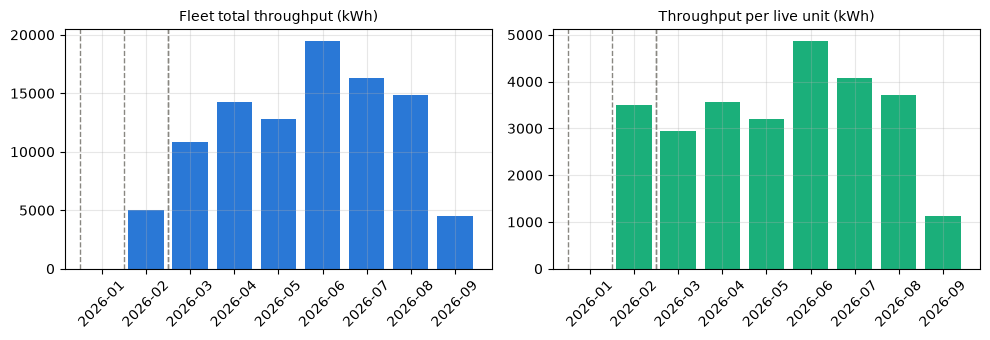

go-live:  SCE-500-0001=2026-01-29, SCE-500-0002=2026-02-17, SCE-500-0003=2026-03-01, SCE-500-0004=2026-03-11


In [3]:
daily_all = []
for ep in endpoints:
    d = daily_throughput(u[u["endpoint_id"] == ep].sort_values("ts_min")).rename("kwh").reset_index().rename(columns={"ts_min": "day"})
    daily_all.append(d)
daily_all = pd.concat(daily_all, ignore_index=True)
daily_all["month"] = pd.to_datetime(daily_all["day"]).dt.to_period("M")
fleet_monthly = daily_all.groupby("month")["kwh"].sum()

go_live = u.groupby("endpoint_id")["ts_min"].min().dt.floor("D")
all_days_range = pd.date_range(u["ts_min"].min().floor("D"), u["ts_min"].max().floor("D"), freq="D")
n_live = pd.Series([sum(go_live[ep] <= d for ep in go_live.index) for d in all_days_range], index=all_days_range)
n_live_monthly = n_live.groupby(n_live.index.to_period("M")).mean()
per_live_unit_monthly = fleet_monthly / n_live_monthly

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
months_str = [str(m) for m in fleet_monthly.index]
axes[0].bar(months_str, fleet_monthly.values, color="#2a78d6")
axes[0].set_title("Fleet total throughput (kWh)", fontsize=10)
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(months_str, per_live_unit_monthly.values, color="#1baf7a")
axes[1].set_title("Throughput per live unit (kWh)", fontsize=10)
axes[1].tick_params(axis="x", rotation=45)
for ax in axes:
    for ep in endpoints:
        m = go_live[ep].to_period("M")
        if str(m) in months_str:
            ax.axvline(months_str.index(str(m)) - 0.5, color="#898781", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

print("go-live: ", ", ".join(f"{ep}={go_live[ep].date()}" for ep in endpoints))


## Usage rhythm

Average fleet throughput by day of week - clear weekday pattern, essentially
no weekend use.


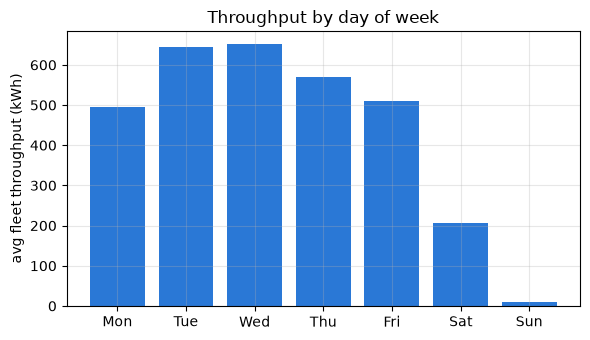

dow
Monday       495.7
Tuesday      643.6
Wednesday    651.0
Thursday     570.0
Friday       509.4
Saturday     205.6
Sunday         9.1
Name: kwh, dtype: float64

In [4]:
daily_all["dow"] = pd.to_datetime(daily_all["day"]).dt.day_name()
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fleet_per_day = daily_all.groupby("day")["kwh"].sum().reset_index()
fleet_per_day["dow"] = pd.to_datetime(fleet_per_day["day"]).dt.day_name()
weekday_kwh = fleet_per_day.groupby("dow")["kwh"].mean().reindex(dow_order)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([d[:3] for d in dow_order], weekday_kwh.values, color="#2a78d6")
ax.set_ylabel("avg fleet throughput (kWh)")
ax.set_title("Throughput by day of week")
plt.tight_layout()
plt.show()
weekday_kwh.round(1)


## Time of use

When during the day the fleet delivers and draws energy. Weekdays only
(weekends run near-zero). Hour is local wall-clock time as recorded in
`ts_min`.


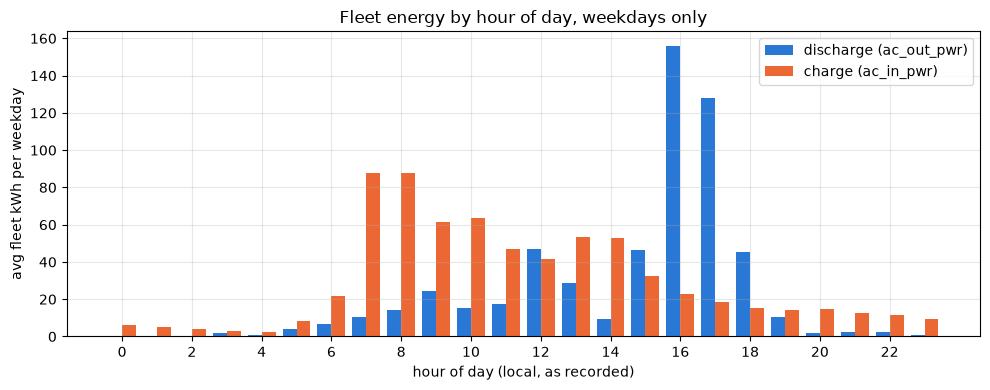

Peak discharge hour: 16:00 (156 kWh/weekday avg, fleet-wide)
Peak charge hour:    07:00 (88 kWh/weekday avg, fleet-wide)


In [5]:
tou = u.copy()
tou["dow"] = tou["ts_min"].dt.day_name()
tou["hour"] = tou["ts_min"].dt.hour
weekday_tou = tou[~tou["dow"].isin(["Saturday", "Sunday"])]
n_weekdays = weekday_tou["ts_min"].dt.floor("D").nunique()

hourly_out = weekday_tou.groupby("hour")["ac_out_pwr"].apply(lambda s: s.clip(lower=0).sum() / 60.0) / n_weekdays
hourly_in = weekday_tou.groupby("hour")["ac_in_pwr"].apply(lambda s: s.clip(lower=0).sum() / 60.0) / n_weekdays

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly_out.index - 0.2, hourly_out.values, width=0.4, label="discharge (ac_out_pwr)", color="#2a78d6")
ax.bar(hourly_in.index + 0.2, hourly_in.values, width=0.4, label="charge (ac_in_pwr)", color="#eb6834")
ax.set_xlabel("hour of day (local, as recorded)")
ax.set_ylabel("avg fleet kWh per weekday")
ax.set_title("Fleet energy by hour of day, weekdays only")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

print(f"Peak discharge hour: {hourly_out.idxmax():02d}:00 ({hourly_out.max():.0f} kWh/weekday avg, fleet-wide)")
print(f"Peak charge hour:    {hourly_in.idxmax():02d}:00 ({hourly_in.max():.0f} kWh/weekday avg, fleet-wide)")


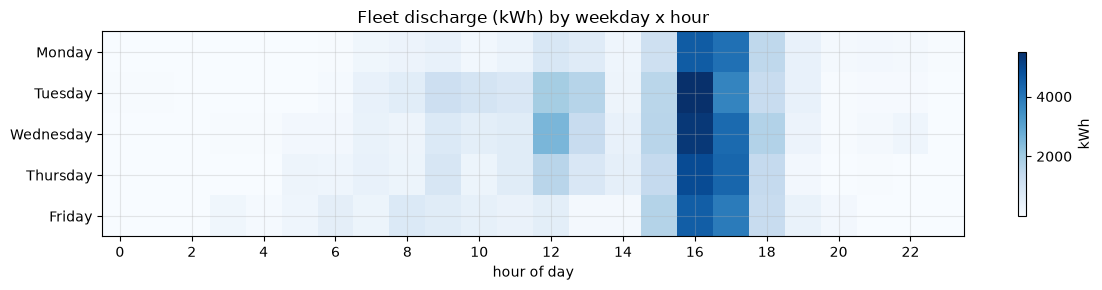

In [6]:
piv_tou = weekday_tou.groupby(["dow", "hour"])["ac_out_pwr"].apply(lambda s: s.clip(lower=0).sum() / 60.0).unstack("hour")
piv_tou = piv_tou.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])

fig, ax = plt.subplots(figsize=(12, 3))
im = ax.imshow(piv_tou.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(piv_tou.index)))
ax.set_yticklabels(piv_tou.index)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_title("Fleet discharge (kWh) by weekday x hour")
fig.colorbar(im, ax=ax, label="kWh", shrink=0.8)
plt.tight_layout()
plt.show()


## Daily intensity, full period

Fleet-wide EFC per day (capacity-normalised, summed across all 4 units), as a
line rather than a calendar heatmap - easier to read the trend and spot
individual high days directly against the timeline. A day with all 4 units
each doing one full cycle would read ~4.0.


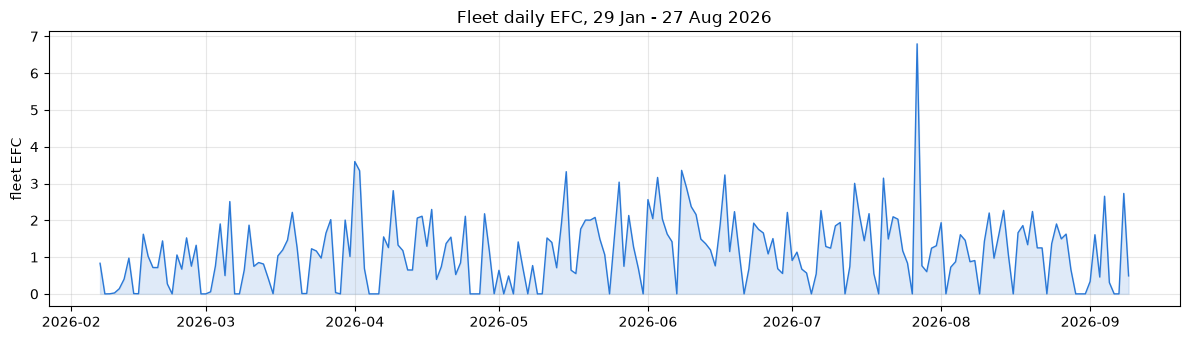

daily mean: 1.16, median: 1.09, max: 6.80


In [7]:
all_cycles = []
for ep in endpoints:
    cycles = cycle_details(u, ep)
    cycles = cycle_energy(u, ep, cycles)
    cycles["start_day"] = pd.to_datetime(cycles["start"]).dt.floor("D")
    cap_at_start = cycles["start_day"].map(capacity_by_day[ep])
    cycles["efc"] = cycles["kwh_out"] / cap_at_start
    cycles["endpoint_id"] = ep
    all_cycles.append(cycles)
all_cycles = pd.concat(all_cycles, ignore_index=True)

fleet_daily_efc = all_cycles.groupby("start_day")["efc"].sum()
full_range = pd.date_range(fleet_daily_efc.index.min(), fleet_daily_efc.index.max(), freq="D")
fleet_daily_efc = fleet_daily_efc.reindex(full_range, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(fleet_daily_efc.index, fleet_daily_efc.values, color="#2a78d6", linewidth=1)
ax.fill_between(fleet_daily_efc.index, fleet_daily_efc.values, color="#2a78d6", alpha=0.15)
ax.set_ylabel("fleet EFC")
ax.set_title("Fleet daily EFC, 29 Jan - 27 Aug 2026")
plt.tight_layout()
plt.show()
print(f"daily mean: {fleet_daily_efc.mean():.2f}, median: {fleet_daily_efc.median():.2f}, max: {fleet_daily_efc.max():.2f}")


## Round-trip efficiency

Per cycle: kWh out / kWh in, restricted to cycles with a meaningful amount of
both (a cycle that re-triggers almost immediately only captures a recharge's
topping-off tail with barely any discharge, which isn't a meaningful reading).
Bars show median efficiency; whiskers span p10-p90.


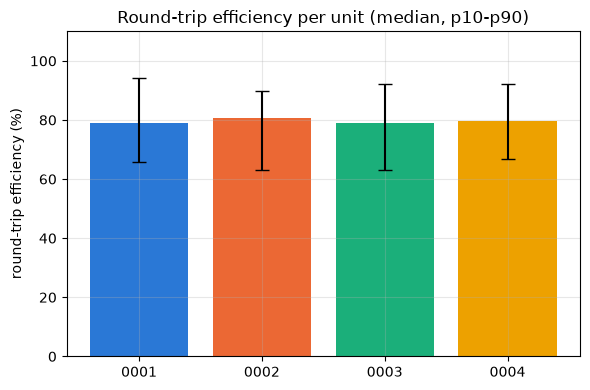

,endpoint_id,n_cycles,mean_eff,median_eff,p10,p90
0,SCE-500-0001,104,0.806,0.789,0.659,0.943
1,SCE-500-0002,74,0.779,0.806,0.631,0.900
2,SCE-500-0003,93,0.810,0.788,0.632,0.922
3,SCE-500-0004,84,0.790,0.796,0.667,0.921


In [8]:
eff_rows = []
for ep in endpoints:
    cycles = cycle_details(u, ep)
    cycles = cycle_energy(u, ep, cycles)
    valid = cycles[(cycles["kwh_in"] > 5) & (cycles["kwh_out"] > 5)]
    eff = valid["kwh_out"] / valid["kwh_in"]
    eff_rows.append({"endpoint_id": ep, "n_cycles": len(valid), "mean_eff": eff.mean(),
                      "median_eff": eff.median(), "p10": eff.quantile(.1), "p90": eff.quantile(.9)})
eff_df = pd.DataFrame(eff_rows)

fig, ax = plt.subplots(figsize=(6, 4))
labels = [ep.replace("SCE-500-", "") for ep in eff_df["endpoint_id"]]
yerr = [(eff_df["median_eff"] - eff_df["p10"]).values, (eff_df["p90"] - eff_df["median_eff"]).values]
ax.bar(labels, eff_df["median_eff"] * 100, color=palette, yerr=[100 * v for v in yerr], capsize=5)
ax.set_ylabel("round-trip efficiency (%)")
ax.set_title("Round-trip efficiency per unit (median, p10-p90)")
ax.set_ylim(0, 110)
plt.tight_layout()
plt.show()
eff_df.round(3)


## Charge time

How long a unit spends actually charging, normalised to an **equivalent time
to a full charge** (each session's own rate, `delta_soc / duration_h`,
projected across a full 0-100% swing). A "charging session" is detected the
same way as the discharge sessions above (power above 1 kW, gaps up to 5
minutes bridged), applied to `ac_in_pwr`, with sessions gaining under 5% SoC
excluded as float/maintenance charging rather than a meaningful charge.


In [9]:
def detect_power_sessions(g, col):
    g = g.dropna(subset=[col]).set_index("ts_min").sort_index()
    active = g[col].abs() > LOAD_ON_THRESHOLD_KW
    active = active.reindex(pd.date_range(g.index.min(), g.index.max(), freq="1min"), fill_value=False)
    run_id = (active != active.shift()).cumsum()
    run_len = active.groupby(run_id).transform("size")
    bridged = active | (~active & (run_len <= SESSION_GAP_MIN))
    session_id = (bridged != bridged.shift(fill_value=False)).cumsum()
    sessions = (
        pd.DataFrame({"active": bridged, "session_id": session_id}).reset_index(names="ts")
        .groupby("session_id").agg(start=("ts", "min"), end=("ts", "max"), active=("active", "first"))
    )
    sessions = sessions[sessions["active"]].copy()
    sessions["duration_h"] = (sessions["end"] - sessions["start"]) / np.timedelta64(1, "h") + (1 / 60)
    return sessions.reset_index(drop=True)

CHARGE_SOC_MIN = 5.0  # a session that gained less SoC than this is float/maintenance charging, not a meaningful charge

all_charge_sessions = []
for ep in endpoints:
    g = u[u["endpoint_id"] == ep].sort_values("ts_min").reset_index(drop=True)
    sess = detect_power_sessions(g, "ac_in_pwr")
    soc_series = g.set_index("ts_min")["soc_avg"]
    sess["soc_start"] = soc_series.reindex(sess["start"], method="nearest").to_numpy()
    sess["soc_end"] = soc_series.reindex(sess["end"], method="nearest").to_numpy()
    sess["delta_soc"] = sess["soc_end"] - sess["soc_start"]
    sess["endpoint_id"] = ep
    all_charge_sessions.append(sess)
all_charge_sessions = pd.concat(all_charge_sessions, ignore_index=True)

meaningful = all_charge_sessions[all_charge_sessions["delta_soc"] >= CHARGE_SOC_MIN].copy()
meaningful["rate_pct_per_h"] = meaningful["delta_soc"] / meaningful["duration_h"]
meaningful["equiv_full_charge_h"] = 100.0 / meaningful["rate_pct_per_h"]

equiv_full = meaningful.groupby("endpoint_id")["equiv_full_charge_h"].agg(
    median_h="median", mean_h="mean", n="size"
).round(2)
equiv_full


,median_h,mean_h,n
endpoint_id,,,
SCE-500-0001,5.60,7.83,161
SCE-500-0002,5.21,7.32,131
SCE-500-0003,5.20,7.84,153
SCE-500-0004,4.09,5.95,131


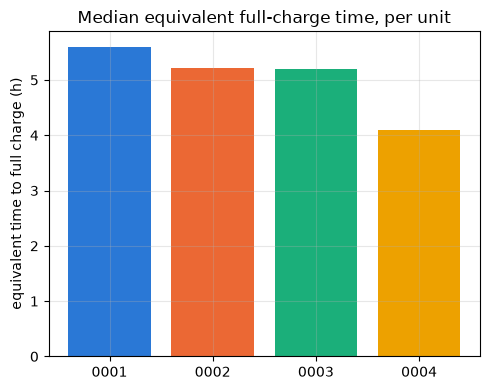

Fleet median equivalent full-charge time: 4.9h


In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar([ep.replace("SCE-500-", "") for ep in endpoints], equiv_full.loc[endpoints, "median_h"], color=palette)
ax.set_ylabel("equivalent time to full charge (h)")
ax.set_title("Median equivalent full-charge time, per unit")
plt.tight_layout()
plt.show()
print(f"Fleet median equivalent full-charge time: {meaningful['equiv_full_charge_h'].median():.1f}h")


## Distribution of usage per unit

**Spread**: boxplot of EFC/day per unit. **Shape**: same data as histograms -
right-skewed with a real tail, a typical day is well under one full cycle but
some days run much deeper.


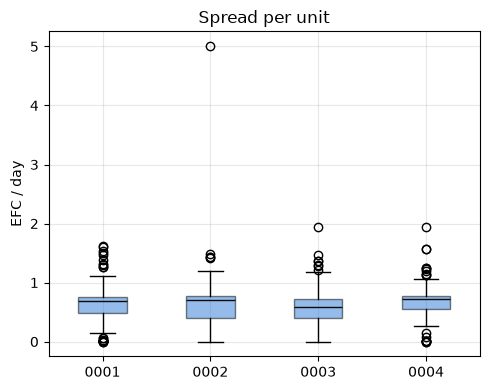

In [11]:
daily_efc_by_unit = {ep: all_cycles[all_cycles["endpoint_id"] == ep].groupby("start_day")["efc"].sum() for ep in endpoints}

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([daily_efc_by_unit[ep].values for ep in endpoints], tick_labels=[ep.replace("SCE-500-", "") for ep in endpoints],
           patch_artist=True, boxprops=dict(facecolor="#2a78d6", alpha=0.5), medianprops=dict(color="#0b0b0b"))
ax.set_ylabel("EFC / day")
ax.set_title("Spread per unit")
plt.tight_layout()
plt.show()


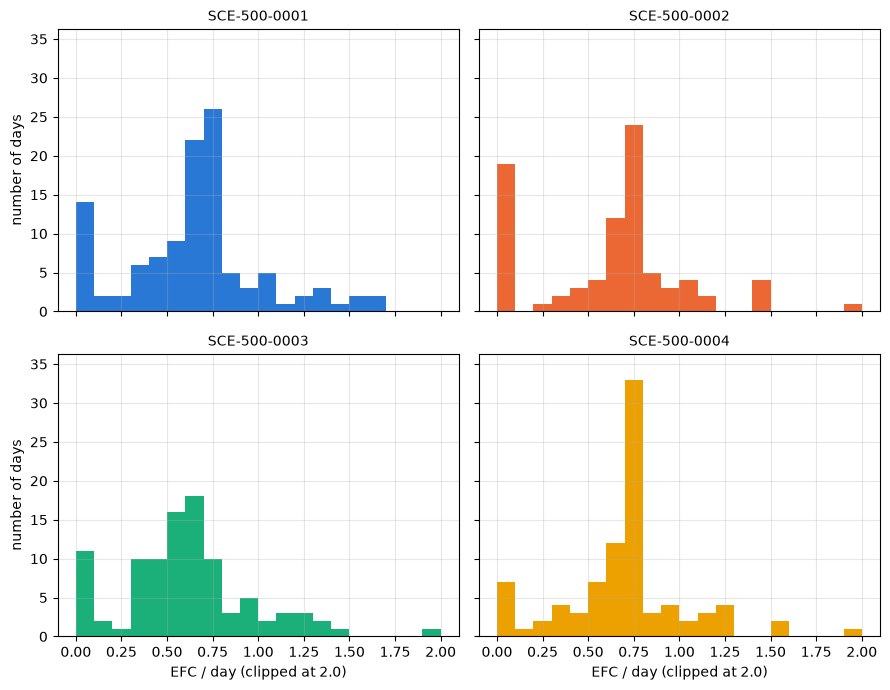

SCE-500-0001: median=0.69, IQR=[0.49, 0.75], p90=1.06, max=1.62
SCE-500-0002: median=0.71, IQR=[0.39, 0.78], p90=1.04, max=5.01
SCE-500-0003: median=0.59, IQR=[0.40, 0.72], p90=1.09, max=1.93
SCE-500-0004: median=0.73, IQR=[0.56, 0.78], p90=1.12, max=1.95


In [12]:
bins = np.linspace(0, 2.0, 21)
xmax_count = max(np.histogram(daily_efc_by_unit[ep].clip(upper=2.0), bins=bins)[0].max() for ep in endpoints)

fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for ax, ep, color in zip(axes.flat, endpoints, palette):
    ax.hist(daily_efc_by_unit[ep].clip(upper=2.0), bins=bins, color=color)
    ax.set_title(ep, fontsize=10)
    ax.set_ylim(0, xmax_count * 1.1)
for ax in axes[1]:
    ax.set_xlabel("EFC / day (clipped at 2.0)")
for ax in axes[:, 0]:
    ax.set_ylabel("number of days")
plt.tight_layout()
plt.show()

for ep in endpoints:
    s = daily_efc_by_unit[ep]
    print(f"{ep}: median={s.median():.2f}, IQR=[{s.quantile(.25):.2f}, {s.quantile(.75):.2f}], "
          f"p90={s.quantile(.9):.2f}, max={s.max():.2f}")
